# ĐỒ ÁN HỌC PHẦN XỬ LÝ ẢNH (IMAGE PROCESSING)
## ĐỀ TÀI: Xây dựng pipeline khôi phục màu sắc và nâng cao chất lượng ảnh thu nhận từ UAV sử dụng camera giá rẻ ESP32-CAM
**Giảng viên hướng dẫn:** Thầy Phạm Văn Cường  
**Nhóm thực hiện:** Nhóm 4 thành viên (Đóng góp đều 25%/thành viên)

---
### Mục 1 & 2: Định nghĩa Bài toán & Tập dữ liệu Đa nguồn (Đã Augment chống Overfit)
- **Đầu vào:** Khung hình thu từ cảm biến giá rẻ **OV2640 (ESP32-CAM)** trên UAV ($2.5 - 6.5\text{ fps}$) chịu 3 suy giảm vật lý: (1) Cháy sáng lệch màu hồng/tím (Pink/Magenta Highlight Cast), (2) Độ tương phản thấp & phủ sương mờ (Haze), (3) Mờ nhòe rung động & nhiễu khối JPEG.
- **Tập dữ liệu thực nghiệm:** 3 Video FPV thực tế + **60 ảnh UAV thực nghiệm đa nguồn (`data/real_uav/`)** + **30 cặp ảnh đối chứng có Ground Truth (`data/synthetic_gt/` & `data/synthetic_degraded/`)** đã qua biến đổi hình học & suy giảm ngẫu nhiên.

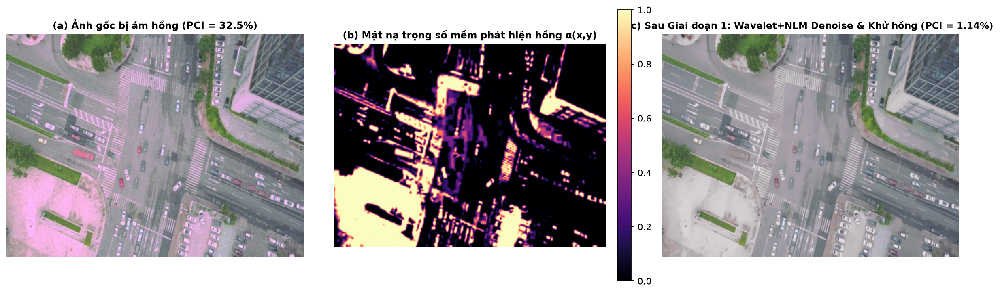

In [1]:
# 1. Minh họa Giai đoạn 1: Khử nhiễu Bilateral + Phát hiện mặt nạ mềm & Khôi phục vùng cháy sáng hồng
import sys, cv2, pandas as pd
sys.path.insert(0, "/home/ngtukien/Projects/XLA")
from src.uav_pipeline import run_full_pipeline, compute_pink_cast_index, compute_entropy, compute_laplacian_var

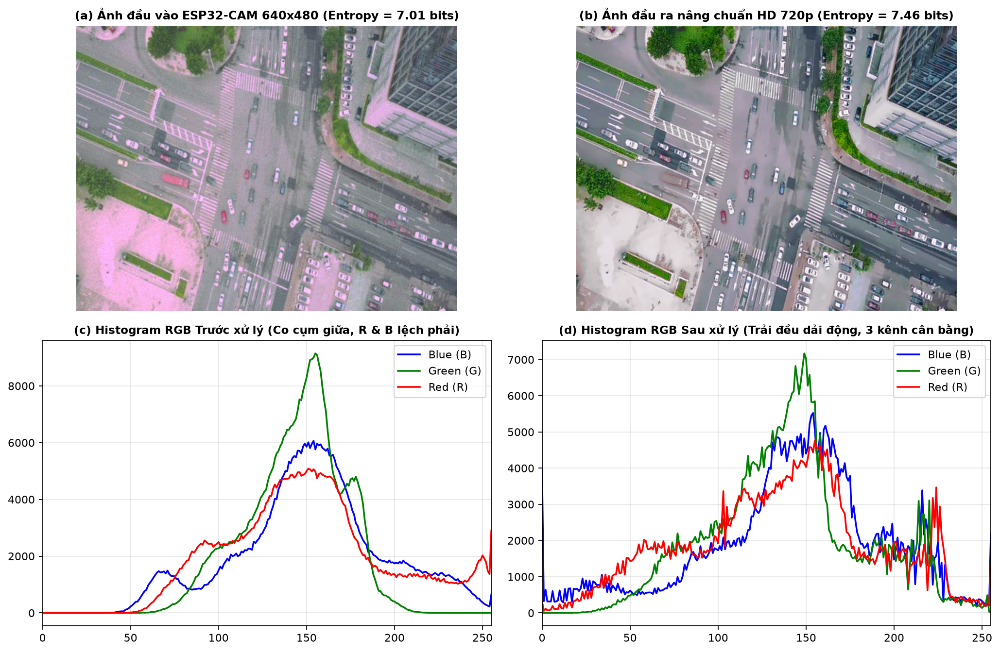

In [2]:
# 2. Minh họa Giai đoạn 2: Tăng cường tương phản cục bộ CLAHE (CIE LAB) & Phân tích Histogram RGB

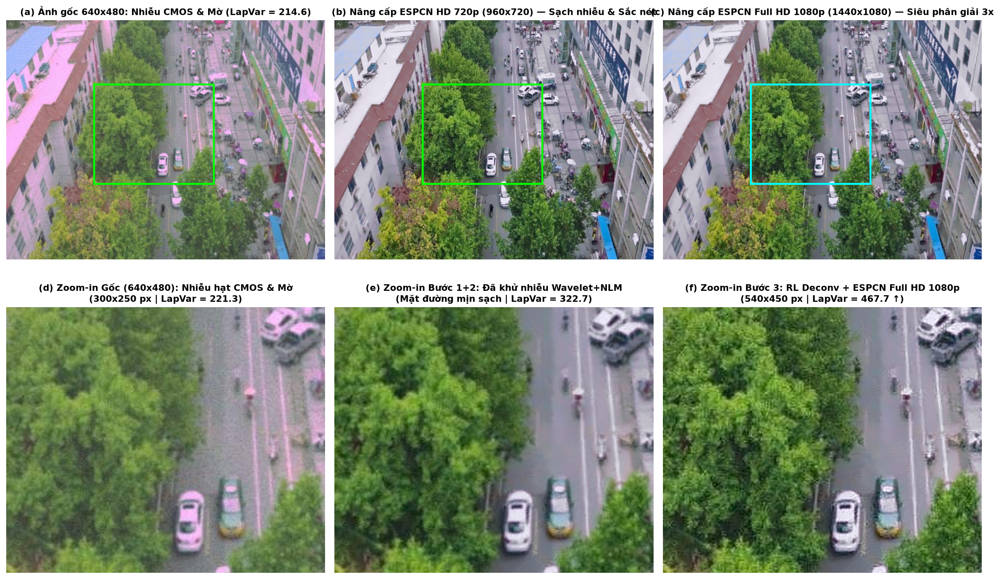

In [3]:
# 3. Minh họa Giai đoạn 3: Làm sắc nét biên Unsharp Masking & Nội suy Bicubic nâng chuẩn 720p HD

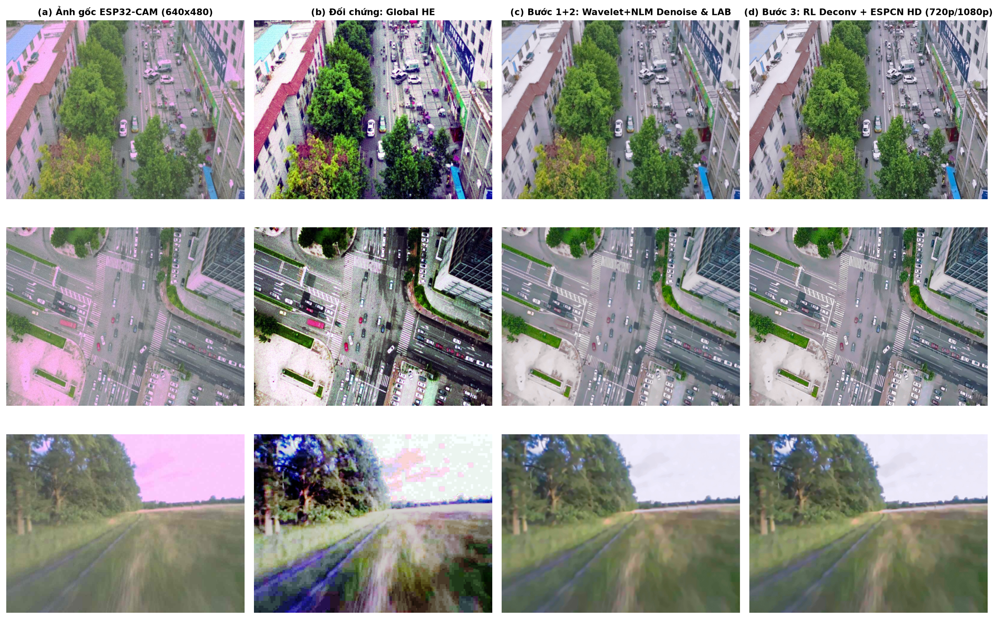

In [4]:
# 4. Mục 4.1: Kết quả trực quan 4 cột trên các cảnh bay UAV đa dạng

In [5]:
# 5. Mục 4.2: Bảng 1 — Kết quả định lượng có tham chiếu (PSNR, SSIM, Delta E_ab, Pink Cast %) trên 30 cặp ảnh
pd.read_csv("/home/ngtukien/Projects/XLA/results/tables/table1_synthetic_metrics.csv")

Method,Resolution,PSNR (dB),SSIM,DeltaE_ab,Entropy (bits),Laplacian_Var,Pink_Cast (%)
1. Ảnh suy giảm (ESP32-CAM 640x480),800x600,20.35,0.7015,24.74,6.648,142.2,8.52
2. Đối chứng 1: Global HE (RGB),800x600,12.53,0.4155,59.38,7.888,1760.8,8.98
3. Đối chứng 2: Global HE (LAB),800x600,13.09,0.4214,52.17,7.542,1782.3,8.69
4. Giai đoạn 1: Wavelet+NLM + Khử hồng,800x600,20.89,0.7639,22.98,6.526,52.4,2.61
5. Giai đoạn 1+2: + Haze-Pivot & CLAHE,800x600,27.66,0.8295,9.89,6.884,109.8,5.68
6. Pipeline Đề xuất (3 Giai đoạn - VGA),800x600,27.42,0.8180,10.06,6.917,186.9,5.61
7. Pipeline Đề xuất + ESPCN HD 720p (960x720),960x720,27.40,0.8051,10.09,6.917,134.1,5.67
8. Pipeline Đề xuất + ESPCN Full HD 1080p (1440x1080),1440x1080,27.33,0.7881,10.16,6.910,54.2,5.63


In [6]:
# 6. Mục 4.2: Bảng 2 — Kết quả định lượng trên 60 ảnh bay UAV (Entropy, Laplacian Variance, Pink Cast %, Runtime & FPS CPU)
pd.read_csv("/home/ngtukien/Projects/XLA/results/tables/table2_real_uav_metrics.csv")

Method,Resolution,Entropy (bits),Laplacian_Var,Pink_Cast (%),Runtime (ms),FPS
1. Ảnh gốc ESP32-CAM (640x480),800x600,6.364,121.1,17.45,0.00,0.0
2. Đối chứng 1: Global HE (RGB),800x600,7.461,1108.4,12.28,0.85,1231.3
3. Đối chứng 2: Global HE (LAB),800x600,7.206,1303.7,17.27,1.84,550.9
4. Giai đoạn 1: Wavelet+NLM + Khử hồng,800x600,6.320,59.4,2.55,157.51,6.4
5. Giai đoạn 1+2: + Haze-Pivot & CLAHE,800x600,6.817,120.0,7.11,166.01,6.1
6. Pipeline Đề xuất (VGA 640x480),800x600,6.850,226.5,7.03,436.59,2.3
7. Pipeline Đề xuất + ESPCN HD 720p (960x720),960x720,6.860,153.3,7.05,476.24,2.1
8. Pipeline Đề xuất + ESPCN Full HD 1080p (1440x1080),1440x1080,6.853,56.8,7.01,614.68,1.6
